In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import fft

import matplotlib.ticker as mticker
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt

import scipy.stats as stats
from sklearn import linear_model
import statsmodels.api as sm
import seaborn as sns

import pymannkendall as mk

# to get rid of runtime warnings when OLS fits hit a divide by zero - handled by setting R2 and p-vals appropriately
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

# latitude & longitude ranges for NH and SH midlatitudes so they will be easy to adjust
nh_min = 23.5
nh_max = 70
sh_min = -60
sh_max = -23.5

In [5]:
file_path1 = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/ACCESS-ESM1-5/regridded/Seasons/1991_ACCESS-ESM1-5_historical_summer_winter_days.nc'
dsnow = xr.open_mfdataset(file_path1)
dsnow

<xarray.Dataset> Size: 50MB
Dimensions:         (lat: 721, lon: 1440)
Coordinates:
  * lat             (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon             (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    FirstWLD        (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    LastWLD         (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    FirstSLD        (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    LastSLD         (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    WinterlikeDays  (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>
    SummerlikeDays  (lat, lon) float64 8MB dask.array<chunksize=(721, 1440), meta=np.ndarray>

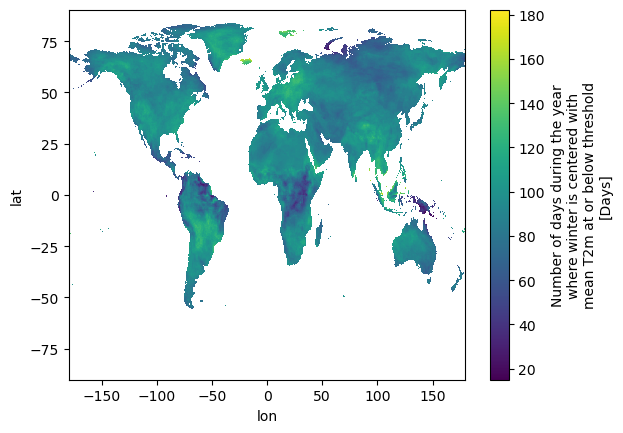

In [6]:
dsnow.WinterlikeDays.plot()

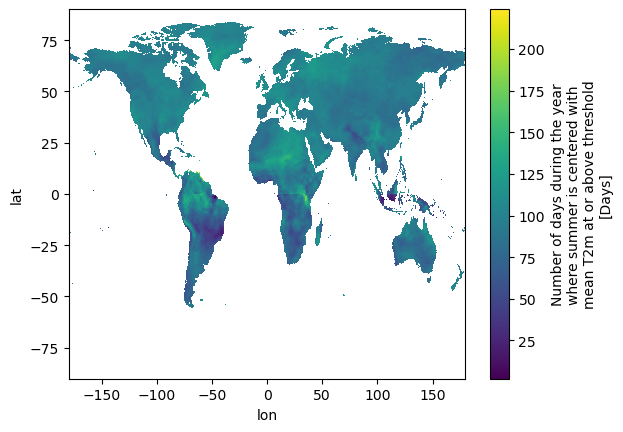

In [7]:
dsnow.SummerlikeDays.plot()

### Add in model and experiment to data files as I did for season lengths

In [ ]:
%%time

for md in models_lst:

    # historical
    intput_years = np.arange(1961, 2015, 1)
    for year in input_years:
        input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_historical_summer_winter_days.nc'
        ds = xr.open_dataset(input_path)
        ds = ds.assign_coords(experiment='historical')
        ds = ds.expand_dims('experiment')
        ds = ds.assign_coords(model=md)
        ds = ds.expand_dims('model')
        # write out updated file
        ds.to_netcdf(input_path)
        

    # ssp245


    # ssp370





## Gather files per model and output full time frame files

In [2]:
%%time
# for each model we need to pull in the individual years files for summer and winter days and collect them into a full file

# Roughly 20-60 min for one model and historical, ssp245, and ssp370 experiments

# comment out as needed
models = [#'ACCESS-ESM1-5',
           #'BCC-CSM2-MR',
           #'CMCC-ESM2',
           #'FGOALS-g3',
           #'GFDL-ESM4',
           #'GISS-E2-1-G',
        #'MIROC-ES2L',
    'MPI-ESM1-2-HR',
        'MIROC6',
    #'MRI-ESM2-0',
           #'NorESM2-LM'
         ]#,'','','','','','','']

# run through the list of models of interest
for md in models:

    start = dt.now()
    
    ######################################################################################################################
    # Historical Period: start with one year and add a coordinate for the year and model
    year = 1961
    input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_historical_summer_winter_days.nc'
    ds_days = xr.open_dataset(input_path)
    ds_days = ds_days.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    
    # loop thru remaining years and also add time coord
    input_years = np.arange(1962,2015,1)
    
    for year in input_years:
        input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_historical_summer_winter_days.nc'
        ds_i = xr.open_dataset(input_path)
        ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
        ds_days = ds_days.merge(ds_i)#.drop_vars(["SummerTmax","SummerRMSE","SummerMeanT","SummerHeat"])

    # assign values for experiment and model before saving
    ds_days = ds_days.assign_coords(experiment='historical')
    ds_days = ds_days.expand_dims('experiment')
    ds_days = ds_days.assign_coords(model=md)
    ds_days = ds_days.expand_dims('model')

    
    # write out historical season lengths dataset 
    output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/1961-2014_'+md+'_historical_summer_winter_days.nc'
    ds_days.to_netcdf(output_path)


    ######################################################################################################################
    # SSP245: start with one year and add a coordinate for the year and model
    year = 2015
    input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_ssp245_summer_winter_days.nc'
    ds_days = xr.open_dataset(input_path)
    ds_days = ds_days.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    
    # loop thru remaining years and also add time coord
    input_years = np.arange(2016,2100,1)
    
    for year in input_years:
        input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_ssp245_summer_winter_days.nc'
        ds_i = xr.open_dataset(input_path)
        ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
        ds_days = ds_days.merge(ds_i)#.drop_vars(["SummerTmax","SummerRMSE","SummerMeanT","SummerHeat"])

    # assign values for experiment and model before saving
    ds_days = ds_days.assign_coords(experiment='ssp245')
    ds_days = ds_days.expand_dims('experiment')
    ds_days = ds_days.assign_coords(model=md)
    ds_days = ds_days.expand_dims('model')
    
    # write out ssp245 season lengths dataset 
    output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/2015-2099_'+md+'_ssp245_summer_winter_days.nc'
    ds_days.to_netcdf(output_path)


    ######################################################################################################################
    # SSP370: start with one year and add a coordinate for the year and model
    year = 2015
    input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_ssp370_summer_winter_days.nc'
    ds_days = xr.open_dataset(input_path)
    ds_days = ds_days.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
    
    # loop thru remaining years and also add time coord
    input_years = np.arange(2016,2100,1)
    
    for year in input_years:
        input_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/'+str(year)+'_'+md+'_ssp370_summer_winter_days.nc'
        ds_i = xr.open_dataset(input_path)
        ds_i = ds_i.expand_dims("time").assign_coords(time=("time", [dt(year,1,1)]))
        ds_days = ds_days.merge(ds_i)#.drop_vars(["SummerTmax","SummerRMSE","SummerMeanT","SummerHeat"])

    # assign values for experiment and model before saving
    ds_days = ds_days.assign_coords(experiment='ssp370')
    ds_days = ds_days.expand_dims('experiment')
    ds_days = ds_days.assign_coords(model=md)
    ds_days = ds_days.expand_dims('model')
    
    # write out ssp370 season lengths dataset 
    output_path = '../../../../Data/CMIP6/NEX-GDDP-CMIP6/'+md+'/regridded/Seasons/2015-2099_'+md+'_ssp370_summer_winter_days.nc'
    ds_days.to_netcdf(output_path)

    # total time for the Model being processed
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+md+" :"+str(elapsed)+" min")

Time for GISS-E2-1-G :404.71874663333335 min
Time for MIROC-ES2L :63.61120545000001 min
CPU times: user 7min 54s, sys: 11min 32s, total: 19min 27s
Wall time: 7h 48min 19s


In [ ]:
ds_days